# Classificação de Clientes com Naive Bayes, Decision Tree e Logistic Regression

Este notebook mostra como transformar os clusters obtidos anteriormente com **K-Means** em rótulos para treinar modelos supervisionados.

## Objetivos da aula

1. Carregar e explorar o dataset;
2. Selecionar as features mais relevantes;
3. Utilizar os rótulos gerados pelo K-Means;
4. Treinar três modelos supervisionados:
   - Naive Bayes;
   - Decision Tree;
   - Logistic Regression;
5. Comparar os resultados dos modelos usando métricas de classificação.

> Observação didática: neste exemplo, os rótulos foram gerados pelo K-Means. Portanto, os modelos supervisionados irão aprender a reproduzir os agrupamentos criados pelo K-Means.


In [1]:
# Importando as principais bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configuração opcional para exibir mais casas decimais
pd.set_option('display.precision', 4)


## 1. Carregando o dataset

Altere o nome do arquivo se necessário.  
O dataset esperado é o mesmo utilizado no exemplo de K-Means com clientes do shopping.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Carregando o dataset
# Ajuste o caminho do arquivo conforme o local onde ele estiver salvo

dataset = pd.read_csv('/content/drive/MyDrive/dataset/Mall_Customers_Rotulado.csv')

# Visualizando as primeiras linhas
dataset.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


## 2. Explorando o dataset

Antes de treinar qualquer modelo, é importante verificar:

- Quantidade de registros;
- Nome das colunas;
- Tipos de dados;
- Presença de valores ausentes.


In [4]:
# Informações gerais do dataset
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
 5   Cluster                 200 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 9.5+ KB


In [5]:
# Estatísticas descritivas
dataset.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster
count,200.0000,200.000,200.0000,200.0000,200.0000
mean,100.5000,38.850,60.5600,50.2000,1.4000
std,57.8792,13.969,26.2647,25.8235,1.4493
min,1.0000,18.000,15.0000,1.0000,0.0000
25%,50.7500,28.750,41.5000,34.7500,0.0000
50%,100.5000,36.000,61.5000,50.0000,1.0000
75%,150.2500,49.000,78.0000,73.0000,3.0000
max,200.0000,70.000,137.0000,99.0000,4.0000


In [6]:
# Verificando valores ausentes
dataset.isnull().sum()


,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0
Cluster,0


## 3. Selecionando as features para o K-Means

Neste exemplo, vamos utilizar as mesmas features do exemplo anterior:

- **Annual Income (k$)**: renda anual;
- **Spending Score (1-100)**: pontuação de gasto.

Essas duas variáveis serão usadas para criar os clusters com K-Means.


In [7]:
# Selecionando as features usadas no K-Means
# Normalmente, no dataset Mall_Customers.csv:
# coluna 3 = Annual Income (k$)
# coluna 4 = Spending Score (1-100)

X_cluster = dataset.iloc[:, [3, 4]].values

X_cluster[:5]


array([[15, 39],
       [15, 81],
       [16,  6],
       [16, 77],
       [17, 40]])

## 4. Preparando os dados para classificação supervisionada

Agora vamos usar os clusters como rótulo.

A variável **X** terá as features de entrada.  
A variável **y** terá o cluster de cada cliente.

Aqui vamos usar as mesmas features do K-Means para manter a aula simples e coerente.


In [8]:
# Features de entrada
X = dataset[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Rótulo gerado pelo K-Means
y = dataset['Cluster'].values

print('Formato de X:', X.shape)
print('Formato de y:', y.shape)


Formato de X: (200, 2)
Formato de y: (200,)


## 5. Dividindo em treino e teste

Vamos separar os dados em:

- **80% para treinamento**;
- **20% para teste**.

O parâmetro `stratify=y` mantém a proporção dos clusters na divisão.


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)


Treino: (160, 2)
Teste: (40, 2)


## 9. Normalizando os dados

A normalização é especialmente importante para:

- **Logistic Regression**, pois o modelo converge melhor com dados em escala semelhante;
- **Naive Bayes**, neste exemplo, para manter a mesma base transformada usada nos modelos probabilísticos/lineares.

A **Decision Tree** não depende tanto de normalização, por isso vamos mantê-la com os dados originais.


In [10]:
scaler = StandardScaler()

# Ajusta o scaler apenas com os dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# Aplica a mesma transformação nos dados de teste
X_test_scaled = scaler.transform(X_test)

X_train_scaled[:5]


array([[-0.25254138, -0.10933747],
       [ 0.64955991, -1.94464497],
       [-0.44047915, -0.34363204],
       [-1.68086842, -1.74939949],
       [-1.5305182 ,  1.02308631]])

## 7. Treinando o modelo Naive Bayes

O Naive Bayes classifica uma nova amostra olhando os vizinhos mais próximos.


In [11]:
nb_model = GaussianNB()

# Naive Bayes pode ser treinado com os dados normalizados neste exemplo
nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

print('Acurácia Naive Bayes:', accuracy_score(y_test, y_pred_nb))
print()
print(classification_report(y_test, y_pred_nb))


Acurácia Naive Bayes: 1.0

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         7
           4       1.00      1.00      1.00         5

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



## 8. Treinando o modelo Decision Tree

A árvore de decisão cria regras do tipo:

> se renda anual > valor X e pontuação de gasto < valor Y, então pertence ao cluster Z.

É um modelo fácil de explicar visualmente.


In [12]:
dt = DecisionTreeClassifier(random_state=42)

# Decision Tree pode usar os dados sem normalização
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print('Acurácia Decision Tree:', accuracy_score(y_test, y_pred_dt))
print()
print(classification_report(y_test, y_pred_dt))


Acurácia Decision Tree: 0.95

              precision    recall  f1-score   support

           0       0.94      1.00      0.97        16
           1       1.00      0.88      0.93         8
           2       1.00      0.75      0.86         4
           3       1.00      1.00      1.00         7
           4       0.83      1.00      0.91         5

    accuracy                           0.95        40
   macro avg       0.95      0.93      0.93        40
weighted avg       0.96      0.95      0.95        40



## 9. Treinando o modelo Logistic Regression

Apesar do nome “regression”, a **Logistic Regression** é muito usada em problemas de classificação.

Neste caso, como temos mais de duas classes, ela trabalha como uma classificação multiclasse.


In [13]:
lr = LogisticRegression(max_iter=1000, random_state=42)

# Logistic Regression usa dados normalizados
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print('Acurácia Logistic Regression:', accuracy_score(y_test, y_pred_lr))
print()
print(classification_report(y_test, y_pred_lr))


Acurácia Logistic Regression: 1.0

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         7
           4       1.00      1.00      1.00         5

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



## 10. Comparando os modelos

Agora vamos comparar a acurácia dos três modelos.


In [14]:
resultados = pd.DataFrame({
    'Modelo': ['Naive Bayes', 'Decision Tree', 'Logistic Regression'],
    'Acurácia': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_lr)
    ]
})

resultados


,Modelo,Acurácia
0,Naive Bayes,1.00
1,Decision Tree,0.95
2,Logistic Regression,1.00


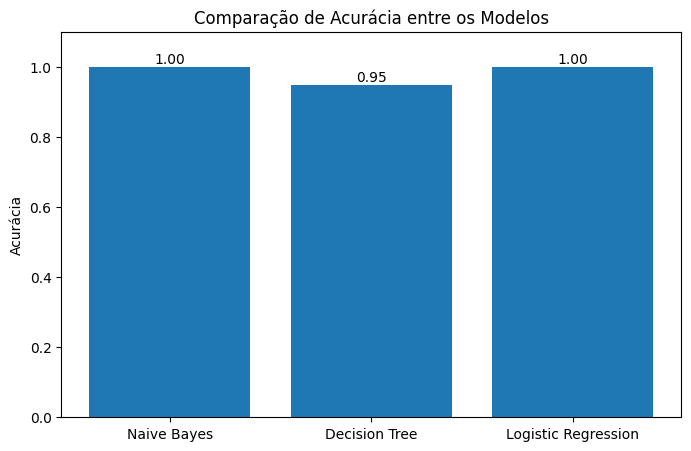

In [15]:
plt.figure(figsize=(8,5))

plt.bar(resultados['Modelo'], resultados['Acurácia'])

for i, v in enumerate(resultados['Acurácia']):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center')

plt.ylim(0, 1.1)
plt.ylabel('Acurácia')
plt.title('Comparação de Acurácia entre os Modelos')
plt.show()


## 11. Matrizes de confusão

A matriz de confusão mostra onde o modelo acertou e onde errou.

As linhas representam as classes reais.  
As colunas representam as classes previstas.


In [16]:
print('Matriz de Confusão - Naive Bayes')
print(confusion_matrix(y_test, y_pred_nb))

print('\nMatriz de Confusão - Decision Tree')
print(confusion_matrix(y_test, y_pred_dt))

print('\nMatriz de Confusão - Logistic Regression')
print(confusion_matrix(y_test, y_pred_lr))


Matriz de Confusão - Naive Bayes
[[16  0  0  0  0]
 [ 0  8  0  0  0]
 [ 0  0  4  0  0]
 [ 0  0  0  7  0]
 [ 0  0  0  0  5]]

Matriz de Confusão - Decision Tree
[[16  0  0  0  0]
 [ 1  7  0  0  0]
 [ 0  0  3  0  1]
 [ 0  0  0  7  0]
 [ 0  0  0  0  5]]

Matriz de Confusão - Logistic Regression
[[16  0  0  0  0]
 [ 0  8  0  0  0]
 [ 0  0  4  0  0]
 [ 0  0  0  7  0]
 [ 0  0  0  0  5]]


## 12. Avaliando as melhores features com Decision Tree

A árvore de decisão permite verificar a importância de cada feature no processo de classificação.


In [17]:
feature_names = ['Annual Income (k$)', 'Spending Score (1-100)']

importancias = pd.DataFrame({
    'Feature': feature_names,
    'Importância': dt.feature_importances_
})

importancias.sort_values(by='Importância', ascending=False)


,Feature,Importância
1,Spending Score (1-100),0.6086
0,Annual Income (k$),0.3914


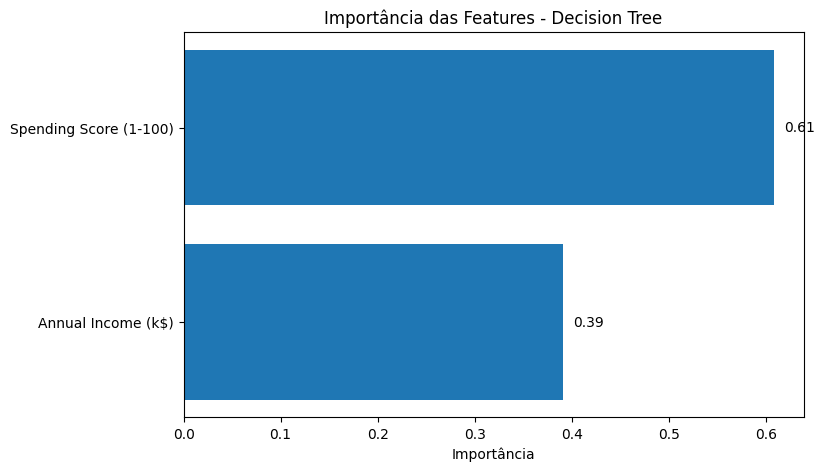

In [18]:
plt.figure(figsize=(8,5))

plt.barh(importancias['Feature'], importancias['Importância'])

for i, v in enumerate(importancias['Importância']):
    plt.text(v + 0.01, i, f'{v:.2f}', va='center')

plt.xlabel('Importância')
plt.title('Importância das Features - Decision Tree')
plt.show()


## 13. Validação cruzada

A validação cruzada avalia o modelo em várias divisões diferentes dos dados.

Isso ajuda a verificar se o desempenho foi consistente ou se dependeu apenas de uma divisão específica de treino/teste.


In [19]:
# Para Naive Bayes e Logistic Regression, usamos dados normalizados
X_scaled = scaler.fit_transform(X)

cv_nb = cross_val_score(nb_model, X_scaled, y, cv=5)
cv_dt = cross_val_score(dt, X, y, cv=5)
cv_lr = cross_val_score(lr, X_scaled, y, cv=5)

cv_resultados = pd.DataFrame({
    'Modelo': ['Naive Bayes', 'Decision Tree', 'Logistic Regression'],
    'Média CV': [cv_nb.mean(), cv_dt.mean(), cv_lr.mean()],
    'Desvio Padrão CV': [cv_nb.std(), cv_dt.std(), cv_lr.std()]
})

cv_resultados


,Modelo,Média CV,Desvio Padrão CV
0,Naive Bayes,0.965,0.0583
1,Decision Tree,0.810,0.2065
2,Logistic Regression,0.955,0.0400
